In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

In [ ]:
df = pd.read_csv("lab2_2_DS.csv")
print(df.head())
print(df.info())

   Temperature (°C)  Ice Cream Sales (units)
0         -4.662263                41.842986
1         -4.316559                34.661120
2         -4.213985                39.383001
3         -3.949661                37.539845
4         -3.578554                32.284531
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes
None


In [ ]:
X = df[["Temperature (°C)"]].values
y = df['Ice Cream Sales (units)'].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [ ]:
degrees = [1, 2, 5, 9]
models = {}
results = []

In [ ]:
for i in degrees:
  model = make_pipeline(PolynomialFeatures(i), LinearRegression()).fit(X_train, y_train)
  y_pred = model.predict(X_test)
  models[i] = model
  results.append({'Степень': i,
                  'MSE': round(mean_squared_error(y_test, y_pred), 4),
                  'R^2': round(r2_score(y_test, y_pred), 4),
                  'MAPE': round(mean_absolute_percentage_error(y_test, y_pred)*100, 2)})

In [ ]:
metrics_df = pd.DataFrame(results)
print(metrics_df.to_string(index=False))

 Степень      MSE     R^2  MAPE
       1 157.5333 -1.2631 64.36
       2  24.6428  0.6460 25.90
       5  35.0212  0.4969 31.83
       9  38.5561  0.4461 28.29


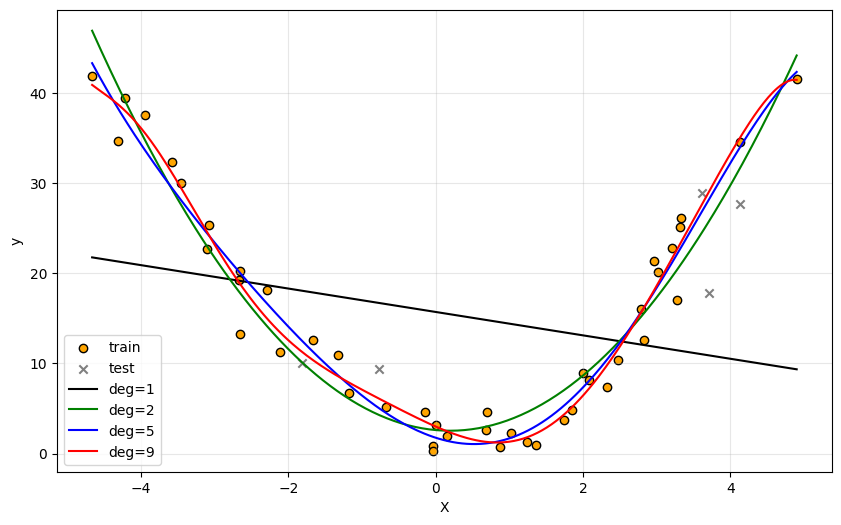

In [ ]:
X_plot = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, c='orange', edgecolor='k', label='train')
plt.scatter(X_test, y_test, c='gray', marker='x', label='test')
for (d, model), color in zip(models.items(), ['black', 'green', 'blue', 'red']):
    plt.plot(X_plot, model.predict(X_plot), color=color, label=f'deg={d}')
plt.xlabel('X'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Лучшая степень по всем метрикам - 2. Степени выше могут привести к переобучению (хуже обобщают данные). Это может быть связано с тем, что данных не большое количество и поэтому самым оптимальным полиномом является  полином степени 2.